# 후보 수와 리랭커 비교

**이 노트북에서 할 일**

1. 07절과 같은 방법으로 개발 질문마다 후보 여덟 개를 만듭니다.
2. 리랭커 두 개를 차례로 만들어 같은 후보에 점수를 냅니다.
3. 후보 수 2·4·8과 방법 세 가지로 아홉 줄을 견줍니다.
4. 보고 자리를 5에서 3으로 줄여 같은 아홉 줄을 다시 봅니다.

**준비물** — 프로젝트 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 문서 청크 1번과 질문 15번으로 모두 열여섯 번입니다.
예상 비용은 미화 0.01달러 아래이고 답을 쓰는 모델은 부르지 않습니다.

리랭커는 내 컴퓨터에서 도는 모델이라 요청 비용이 들지 않습니다.
처음 실행할 때 리랭커 두 개의 파일을 각각 약 2.2GB씩 내려받습니다.
그다음부터는 받아 둔 파일을 쓰고 판 번호를 고정해 같은 파일을 씁니다.
실행 시간은 내려받기를 빼고 3분 안팎이며 리랭커 호출이 가장 오래 걸립니다.

**메모리** — 리랭커 하나를 살려 두는 데 약 2.5GB가 듭니다.
두 모델을 함께 살려 두지 않도록 한 모델을 다 쓴 뒤 다음 모델을 만듭니다.

**데이터** — 두 파일 모두 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/advanced-documents.json`(부모 6건·문서 청크 175개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/advanced-queries.json`(30개)

**강의와 실습 범위** — 강의 시간에는 2~4절과 8~10절을 읽습니다.
후보와 지표를 정하는 자리가 2~4절이고 리랭커 두 개를 부르는 자리가 8절입니다.
9절이 실행 1이고 10절이 값 바꿔 보기입니다.
1·5~7·11절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 첫 셀에서 여섯 패키지를 고정한 판으로 설치합니다.
리랭커는 판 번호 `953dc6f6f85a`와 `8c2ab1a83373`을 고정해 받습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

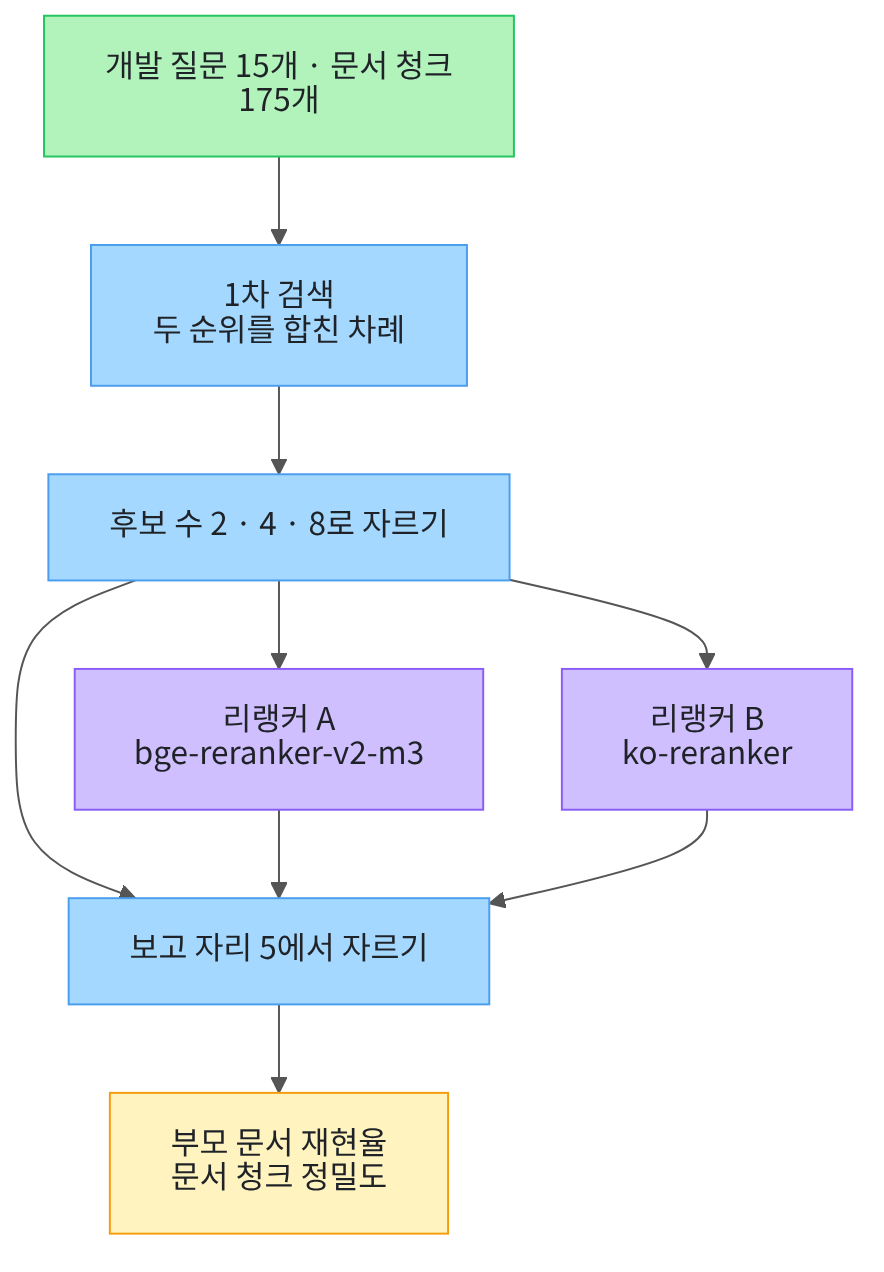

맨 위 초록 상자가 이 절이 쓰는 질문 묶음과 문서 청크 묶음입니다.
그 아래 파란 상자 두 개가 후보를 만들고 후보 수로 자르는 자리입니다.
보라 상자 둘이 견줄 리랭커이고 가운데 갈래는 리랭커를 거치지 않는 1차 후보입니다.
세 갈래가 다시 파란 상자 보고 자리로 모여 같은 자리에서 잘립니다.
맨 아래 노란 상자가 이 노트북 9절이 내는 두 지표입니다.

## 1. 준비

첫 셀은 패키지 여섯 개를 설치하고 설치된 버전을 출력합니다.
07절과 같은 여섯 개이고 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2" "sentence-transformers==6.0.1" "numpy==2.5.3"
from importlib.metadata import version

print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))
print("sentence-transformers:", version("sentence-transformers"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.


langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2
sentence-transformers: 6.0.1
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 `langchain-openai: 1.6.1`과 `sentence-transformers: 6.0.1`이 보입니다.
마지막 줄 `numpy: 2.5.3`은 도구 파일이 벡터 계산에 쓰는 패키지입니다. 여섯 줄이 모두 보이면 다음 셀로 넘어갑니다.

다음 셀은 이 절에서 쓸 이름 다섯 개를 불러옵니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 04·06·07절 함수 세 개와 Ch 11 `recall_at()`을 가져옵니다.
04절 `kiwi_terms()`, 06절 `fuse_rank()`, 07절 `parent_ids_of()`입니다.
07절과 같은 문서 청크 판 순위 함수 세 개도 함께 가져옵니다.
인자 모양이 앞 절 판과 다른 함수는 5절과 6절에서 설명합니다.

In [2]:
# 자료 읽기·형태소 분석·임베딩·낱말 점수·리랭커에 쓸 이름을 불러옵니다
import json
import os
import warnings

# 리랭커 파일을 읽을 때 나오는 진행 막대와 위젯 경고는 계산과 관계없어 화면에 내지 않습니다
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")

from kiwipiepy import Kiwi
from langchain_openai import OpenAIEmbeddings
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder
# 04·06·07절과 Ch 11 함수, 01~06절 순위 함수의 문서 청크 판 일곱 개를 도구 파일에서 가져옵니다
from rag_tools import fuse_rank, kiwi_terms, parent_ids_of, rank_chunks_by_bm25
from rag_tools import rank_chunks_by_distance, recall_at, unique_chunk_ids

print("불러온 이름:", "json", "Kiwi", "OpenAIEmbeddings", "BM25Okapi", "CrossEncoder")

불러온 이름: json Kiwi OpenAIEmbeddings BM25Okapi CrossEncoder


**결과 읽기** — 출력 줄은 `불러온 이름:` 뒤에 이름 다섯 개가 붙은 한 줄입니다.
도구 파일에서 가져온 함수 일곱 개는 출력하지 않습니다.

다음 셀은 API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True` 하나입니다.
키 값은 출력하지 않습니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~07절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.

다음 셀은 07절과 같은 자료 두 벌을 읽습니다.

In [5]:
# 07절과 같은 문서 파일과 질문 파일을 불러옵니다
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/advanced-documents.json", encoding="utf-8") as file:
    documents = json.loads(file.read())
with open(data_path + "/advanced-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
parents = documents["parents"]
chunks = documents["chunks"]
print("부모 문서 수:", len(parents))
print("문서 청크 수:", len(chunks))
print("질문 수:", len(queries))

부모 문서 수: 6
문서 청크 수: 175
질문 수: 30


**결과 읽기** — `부모 문서 수: 6`과 `문서 청크 수: 175`, `질문 수: 30`이 보입니다.
07절과 같은 파일이라 세 값도 같습니다.

## 2. 개발 묶음 가리기

Ch 11이 정한 약속은 개발 15문항으로 설정을 고르는 것입니다.
시험 15문항은 설정을 다 고른 뒤 12절에서 한 번만 씁니다.
이 절도 그 약속을 지켜 개발 묶음만 봅니다.
개발 묶음 안에서도 답할 수 없는 질문과 정답 ID가 빈 질문은 지표에서 뺍니다.
다음 셀은 그 두 가지를 거르는 함수입니다.

In [6]:
# 답할 수 있고 정답 부모 문서 ID가 있는 질문만 남깁니다
def eligible_items(subset):
    picked = []
    for item in subset:
        gold_ids = []
        # 같은 정답 ID가 두 번 적혀 있으면 지표의 나누는 수가 달라져 한 번만 둡니다
        for gold_id in item["gold_doc_ids"]:
            if gold_id not in gold_ids:
                gold_ids.append(gold_id)
        item["gold_doc_ids"] = gold_ids
        if item["answerable"] and len(gold_ids) > 0:
            picked.append(item)
    return picked

**결과 읽기** — 정의 셀이라 출력이 없습니다.
같은 정답 ID가 두 번 적혀 있으면 한 번만 남깁니다.
지표 함수가 정답 ID 개수로 나누기 때문에 겹친 값을 그대로 두면 값이 달라집니다.

다음 셀은 그 함수로 개발 묶음을 가립니다.

In [7]:
# 질문 30개에서 개발 묶음만 고르고 답할 수 있는 질문만 남깁니다
dev_all = []
for query in queries:
    if query["split"] == "dev":
        dev_all.append(query)
dev_queries = eligible_items(dev_all)
print("개발 질문 수:", len(dev_queries))
print("시험 질문 수:", len(queries) - len(dev_all))
print("첫 개발 질문:", dev_queries[0]["qid"], "|", dev_queries[0]["question"])
print("그 질문의 정답 부모 문서 ID:", dev_queries[0]["gold_doc_ids"])

개발 질문 수: 15
시험 질문 수: 15
첫 개발 질문: Q001 | 미르시립도서관의 정기 휴관일은 언제인가요?
그 질문의 정답 부모 문서 ID: ['E01']


**결과 읽기** — `개발 질문 수: 15`와 `시험 질문 수: 15`가 보입니다.
줄 `첫 개발 질문:` 뒤에 질문 ID와 질문 글이 있습니다.
정답 칸 값은 `['E01']`처럼 목록입니다.
이번 개발 묶음에서는 빠진 질문이 없어 열다섯 개가 그대로 남았습니다.

## 3. 이 절에서 쓸 값 정하기

01~07절에서 쓴 값 세 개를 그대로 다시 정합니다.

In [8]:
# 01~07절에서 쓴 값을 그대로 다시 정합니다
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
rank_constant = 60
equal_weights = [1.0, 1.0]
print("남길 품사 표시:", keep_tags)
print("순위 상수:", rank_constant)
print("같은 가중치:", equal_weights)

남길 품사 표시: ['NNG', 'NNP', 'NNB', 'NR', 'VV', 'VA', 'MAG', 'SN', 'SL']
순위 상수: 60
같은 가중치: [1.0, 1.0]


**결과 읽기** — 줄 `순위 상수: 60`과 `같은 가중치: [1.0, 1.0]`은 06·07절과 같은 값입니다.
라벨 줄 `남길 품사 표시:` 뒤에는 이름 아홉 개가 있습니다.

다음 셀은 이 절에서 견줄 값을 정합니다.
후보 수는 리랭커가 볼 수 있는 문서 청크 수입니다.
보고 자리는 검색 결과에서 다음 단계로 넘길 문서 청크 수입니다.

In [9]:
# 이 절에서 견줄 후보 수·지표를 재는 자리·리랭커 두 개를 정합니다
candidate_count = 8
candidate_counts = [2, 4, 8]
recall_place = 3
report_place = 5
method_names = ["1차 후보", "리랭커 A", "리랭커 B"]
reranker_names = ["BAAI/bge-reranker-v2-m3", "Dongjin-kr/ko-reranker"]
first_revision = "953dc6f6f85a1b2dbfca4c34a2796e7dde08d41e"
second_revision = "8c2ab1a833734491fd3158164dd2b7d8b28e071c"
reranker_revisions = [first_revision, second_revision]
reranker_max_length = 256
print("견줄 후보 수 세 가지:", candidate_counts)
print("부모 문서 재현율을 재는 자리:", recall_place)
print("보고 자리:", report_place)
print("견줄 방법 세 가지:", method_names)

견줄 후보 수 세 가지: [2, 4, 8]
부모 문서 재현율을 재는 자리: 3
보고 자리: 5
견줄 방법 세 가지: ['1차 후보', '리랭커 A', '리랭커 B']


**결과 읽기** — `견줄 후보 수 세 가지: [2, 4, 8]`과 `보고 자리: 5`가 보입니다.
줄 `부모 문서 재현율을 재는 자리: 3`은 07절에서 쓴 자리와 같습니다.
라벨 줄 `견줄 방법 세 가지:` 뒤에 이름 셋이 있고 그 셋이 표의 왼쪽 칸이 됩니다.
리랭커 두 개의 이름과 판 번호도 이 셀에서 정했습니다.

## 4. 두 지표가 볼 재료 만들기

문서 청크마다 제목과 본문을 이어 붙여 글 하나로 만듭니다.
청크 ID로 부모 문서 ID와 글을 찾을 수 있게 짝도 함께 만들어 둡니다.

In [10]:
# 문서 청크마다 제목과 본문을 이어 붙이고 청크 ID·부모 문서 ID·글을 짝지어 둡니다
chunk_texts = []
chunk_ids = []
parent_by_chunk = {}
text_by_chunk = {}
for chunk in chunks:
    chunk_text = chunk["title"] + " " + chunk["text"]
    chunk_texts.append(chunk_text)
    chunk_ids.append(chunk["chunk_id"])
    parent_by_chunk[chunk["chunk_id"]] = chunk["parent_id"]
    text_by_chunk[chunk["chunk_id"]] = chunk_text
all_chunk_count = len(chunk_ids)
print("이어 붙인 글 수:", len(chunk_texts))
print("첫 문서 청크 ID:", chunk_ids[0])

이어 붙인 글 수: 175
첫 문서 청크 ID: E01-P01-C01


**결과 읽기** — `이어 붙인 글 수: 175`가 보입니다.
줄 `첫 문서 청크 ID: E01-P01-C01`의 이름은 부모 ID와 쪽 번호, 문서 청크 번호를 이은 것입니다.

다음 셀은 벡터 거리 쪽 재료를 만듭니다. 01~07절과 같은 모델을 씁니다.

In [11]:
# 01~07절과 같은 모델로 문서 청크와 개발 질문을 벡터로 바꿉니다(임베딩 요청 16번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
chunk_vectors = embedding_model.embed_documents(chunk_texts)
query_vectors = []
for query in dev_queries:
    query_vectors.append(embedding_model.embed_query(query["question"]))
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 청크 벡터 수:", len(chunk_vectors))
print("질문 벡터 수:", len(query_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 청크 벡터 수: 175
질문 벡터 수: 15


**결과 읽기** — `벡터의 숫자 개수 설정: 256`과 `문서 청크 벡터 수: 175`가 보입니다.
출력 줄 `질문 벡터 수: 15`까지 나오면 임베딩 요청 열여섯 번이 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

다음 셀은 문서 청크의 검색 낱말 목록으로 BM25 모델을 만듭니다.
검색 낱말은 07절처럼 도구 파일의 `kiwi_terms()`에 분석기와 남길 품사 표시를 넘겨 만듭니다.
분석기를 만드는 줄 `kiwi = Kiwi()`는 1초 안팎 걸립니다.

In [12]:
# 04~07절과 같은 형태소 분석기로 문서 청크마다 검색 낱말 목록을 만들고 BM25 모델을 만듭니다
kiwi = Kiwi()
kiwi_corpus = []
for text in chunk_texts:
    kiwi_corpus.append(kiwi_terms(kiwi, text, keep_tags))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 청크 수:", bm25_model.corpus_size)
print("문서 청크 하나의 평균 검색 낱말 수:", round(bm25_model.avgdl, 2))

검색 낱말 목록 수: 175
BM25 모델이 본 문서 청크 수: 175
문서 청크 하나의 평균 검색 낱말 수: 44.01


**결과 읽기** — `검색 낱말 목록 수: 175`와 `BM25 모델이 본 문서 청크 수: 175`가 보입니다.
줄 `문서 청크 하나의 평균 검색 낱말 수: 44.01`은 07절과 같은 값입니다.

## 5. 1차 검색 함수의 인자 확인하기

1차 검색 함수는 07절과 같은 판을 준비 셀에서 도구 파일로부터 가져왔습니다.
함수 `rank_chunks_by_distance()`와 `rank_chunks_by_bm25()`가 두 순위를 만듭니다.
값 칸 이름은 `거리`와 `점수`이고 문서 청크 ID는 칸 `chunk_id`에 있습니다.
함수 `unique_chunk_ids()`는 그 순위 목록에서 문서 청크 ID만 차례로 모읍니다.
06절 `fuse_rank()`는 순위 상수를 셋째 인자로 받습니다.

## 6. 후보 목록 만들기

개발 질문마다 두 순위를 만들어 합치고 앞자리 여덟 개를 후보로 자릅니다.
07절과 같은 1차 검색이라 후보 목록도 같습니다.
이 셀은 1차 차례를 그대로 점수로도 남깁니다.
그래야 리랭커를 거치지 않은 차례도 같은 함수로 잴 수 있습니다.

In [13]:
# 개발 질문마다 두 순위를 합쳐 앞자리 여덟 개를 후보로 자르고 1차 차례도 점수로 남깁니다
candidate_sets = {}
first_scored = {}
place_scores = []
# 자리 번호에 음수를 붙이면 앞자리가 큰 점수가 되어 1차 차례를 그대로 쓸 수 있습니다
for position in range(candidate_count):
    place_scores.append(0 - position)
for query_index in range(len(dev_queries)):
    question_id = dev_queries[query_index]["qid"]
    distance_hits = rank_chunks_by_distance(query_vectors[query_index], chunk_vectors, chunk_ids, all_chunk_count)
    question_terms = kiwi_terms(kiwi, dev_queries[query_index]["question"], keep_tags)
    score_hits = rank_chunks_by_bm25(bm25_model, question_terms, chunk_ids, all_chunk_count)
    ranking_list = [unique_chunk_ids(distance_hits), unique_chunk_ids(score_hits)]
    candidate_sets[question_id] = fuse_rank(ranking_list, equal_weights, rank_constant)[:candidate_count]
    first_scored[question_id] = place_scores
print("만든 후보 목록 수:", len(candidate_sets))
print("후보 목록 하나의 문서 청크 수:", len(candidate_sets[dev_queries[0]["qid"]]))

만든 후보 목록 수: 15
후보 목록 하나의 문서 청크 수: 8


**결과 읽기** — `만든 후보 목록 수: 15`와 `후보 목록 하나의 문서 청크 수: 8`이 보입니다.
개발 질문 하나에 후보 목록 하나가 만들어졌습니다.
후보 수를 2와 4로 줄일 때는 이 여덟 개의 앞쪽만 씁니다.

문서 청크 ID 목록을 부모 문서 ID 목록으로 바꾸는 일은 07절 `parent_ids_of()`가 맡습니다.
질문 파일의 정답이 부모 문서 ID라 재현율을 재기 전에 이 단계가 필요합니다.
도구 파일 판은 07절 판이 바로 읽던 짝 사전 `parent_by_chunk`를 둘째 인자로 받습니다.

## 7. 리랭커 호출과 다시 정렬 함수

다음 셀은 질문과 후보 본문을 쌍으로 묶어 점수를 받는 함수입니다.
07절과 같은 호출이고 쓰는 리랭커만 이름 `reranker`로 바뀝니다.

In [14]:
# 질문 하나와 후보 본문을 쌍으로 묶어 리랭커에서 점수 목록을 받습니다(07절과 같은 호출)
def score_candidates(question, found_chunk_ids):
    pairs = []
    for chunk_id in found_chunk_ids:
        # 쌍 하나는 (질문, 후보 본문) 모양의 튜플입니다
        pairs.append((question, text_by_chunk[chunk_id]))
    scores = reranker.predict(pairs, show_progress_bar=False)
    # predict가 주는 값은 넘파이 배열이라 tolist()로 파이썬 목록으로 바꿉니다
    return scores.tolist()

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 함수는 부를 때마다 이름 `reranker`가 가리키는 모델을 씁니다.

다음 셀은 받은 점수로 후보를 다시 놓는 함수입니다.
인자 `candidate_k`가 후보를 앞에서 몇 개까지 볼지 정합니다.

In [15]:
# 후보를 앞에서 candidate_k개만 남기고 점수가 큰 순서로 다시 놓습니다
def order_by_score(question_id, scored, candidate_k):
    found_chunk_ids = candidate_sets[question_id][:candidate_k]
    score_list = scored[question_id]
    pairs = []
    for i in range(len(found_chunk_ids)):
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - score_list[i], found_chunk_ids[i]))
    ranked_ids = []
    for pair in sorted(pairs):
        ranked_ids.append(pair[1])
    return ranked_ids

**결과 읽기** — 정의 셀이라 출력이 없습니다.
1차 차례를 점수로 바꿔 둔 목록을 넣으면 자른 차례가 그대로 나옵니다.

## 8. 리랭커 두 개로 점수 내기

리랭커 두 개를 차례로 만들어 같은 후보에 점수를 냅니다.
모델 하나를 살려 두는 데 약 2.5GB가 들어 두 모델을 함께 두지 않습니다.
이름 `reranker`에 `None`을 넣으면 앞 모델이 메모리에서 내려갑니다.
이 셀은 리랭커를 서른 번 불러 2분 안팎 걸립니다.

In [16]:
# 리랭커 두 개를 차례로 만들어 개발 질문의 후보에 점수를 냅니다(리랭커 호출 30번)
scored_by_method = {}
scored_by_method[method_names[0]] = first_scored
for model_index in range(len(reranker_names)):
    # 다음 모델을 만들기 전에 이름에 None을 넣어 앞 모델을 메모리에서 내려놓습니다
    reranker = None
    reranker = CrossEncoder(
        reranker_names[model_index], revision=reranker_revisions[model_index],
        max_length=reranker_max_length, device="cpu")
    scored = {}
    for item in dev_queries:
        scored[item["qid"]] = score_candidates(item["question"], candidate_sets[item["qid"]])
    scored_by_method[method_names[model_index + 1]] = scored
print("점수를 낸 방법 수:", len(scored_by_method))
print("리랭커 A:", reranker_names[0], "|", first_revision[:12])
print("리랭커 B:", reranker_names[1], "|", second_revision[:12])
print("한 쌍에서 읽는 최대 조각 수:", reranker.max_seq_length)

점수를 낸 방법 수: 3
리랭커 A: BAAI/bge-reranker-v2-m3 | 953dc6f6f85a
리랭커 B: Dongjin-kr/ko-reranker | 8c2ab1a83373
한 쌍에서 읽는 최대 조각 수: 256


**결과 읽기** — `점수를 낸 방법 수: 3`이 보입니다.
방법 셋은 1차 후보와 리랭커 두 개입니다.
줄 `리랭커 A:`와 `리랭커 B:` 뒤에 모델 이름과 판 번호 앞 열두 글자가 있습니다.
출력 줄 `한 쌍에서 읽는 최대 조각 수: 256`은 두 모델에 같게 준 값입니다.
출력 맨 위의 영문 알림은 계정을 밝히지 않고 파일을 받았다는 뜻입니다.

## 9. 실행 1 — 아홉 줄 견주기

지표는 두 가지입니다.
재현율은 준비 셀에서 가져온 Ch 11 함수 `recall_at()`으로 냅니다.
자르는 자리까지 자른 목록에 정답 부모가 있으면 1.0이 나옵니다.

다음 셀은 이 절에서 새로 만드는 문서 청크 정밀도입니다.
재현율은 정답 개수로 나누고 이 지표는 보고 자리로 나눕니다.

In [17]:
# 앞자리 문서 청크 가운데 정답 부모 문서에서 나온 것을 세어 보고 자리로 나눕니다
def chunk_precision_at(found_chunk_ids, gold_doc_ids, cutoff):
    top_ids = found_chunk_ids[:cutoff]
    found_count = 0
    for chunk_id in top_ids:
        # 나누는 수가 보고 자리라 자리를 다 채우지 못하면 값이 내려갑니다
        if parent_by_chunk[chunk_id] in gold_doc_ids:
            found_count = found_count + 1
    return found_count / cutoff

**결과 읽기** — 정의 셀이라 출력이 없습니다.
후보가 보고 자리보다 적으면 남은 자리가 비어 값이 내려갑니다.

다음 셀은 방법 하나를 개발 질문 열다섯 개로 재는 함수입니다.
반환값은 두 지표의 질문 평균 두 개입니다.

In [18]:
# 방법 하나의 점수로 개발 질문을 모두 재어 두 지표의 질문 평균을 냅니다
def evaluate(scored, candidate_k):
    if len(dev_queries) == 0:
        raise ValueError("평가 가능한 개발 문항이 없습니다")
    recall_total = 0.0
    precision_total = 0.0
    for item in dev_queries:
        gold_ids = item["gold_doc_ids"]
        ranked_ids = order_by_score(item["qid"], scored, candidate_k)
        parent_ids = parent_ids_of(ranked_ids, parent_by_chunk)
        recall_total = recall_total + recall_at(parent_ids, gold_ids, recall_place)
        precision_total = precision_total + chunk_precision_at(ranked_ids, gold_ids, report_place)
    return round(recall_total / len(dev_queries), 3), round(precision_total / len(dev_queries), 3)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
잴 질문이 하나도 없으면 오류를 내고 멈춥니다.

다음 셀이 이 절의 실행 1입니다.
실행 전에 예상해 봅니다. 후보 수를 늘리면 문서 청크 정밀도가 오를 것입니다.

In [19]:
# 방법 세 가지와 후보 수 세 가지로 두 지표의 질문 평균을 냅니다
print("방법 | 후보 수 | 부모 문서 재현율 자리", recall_place, "| 문서 청크 정밀도 자리", report_place)
for method_name in method_names:
    scored = scored_by_method[method_name]
    for candidate_k in candidate_counts:
        means = evaluate(scored, candidate_k)
        print(method_name, "|", candidate_k, "|", means[0], "|", means[1])

방법 | 후보 수 | 부모 문서 재현율 자리 3 | 문서 청크 정밀도 자리 5
1차 후보 | 2 | 1.0 | 0.4
1차 후보 | 4 | 1.0 | 0.693
1차 후보 | 8 | 1.0 | 0.84
리랭커 A | 2 | 1.0 | 0.4
리랭커 A | 4 | 1.0 | 0.693
리랭커 A | 8 | 1.0 | 0.893
리랭커 B | 2 | 1.0 | 0.4
리랭커 B | 4 | 1.0 | 0.693
리랭커 B | 8 | 1.0 | 0.867


**결과 읽기** — 라벨 줄 아래 아홉 줄이 나옵니다.
부모 문서 재현율 칸은 아홉 줄이 모두 `1.0`입니다.
문서 청크 정밀도 칸은 후보 2에서 세 방법이 모두 `0.4`입니다.
후보 8에서는 `1차 후보 | 8 | 1.0 | 0.84`와 `리랭커 A | 8 | 1.0 | 0.893`으로 갈립니다.
리랭커 B는 같은 자리에서 `0.867`입니다.

부모 문서 재현율은 아홉 줄이 모두 같아 이 조건에서는 방법을 가를 수 없습니다.
부모 문서가 6건뿐이고 1차 후보가 이미 정답 부모를 자리 1에 두었기 때문입니다.
문서 청크 정밀도는 후보 수에 따라 크게 달라졌습니다.
후보 2에서는 보고 자리 다섯 가운데 두 자리만 채워 최댓값이 `0.4`입니다.

다음 셀은 후보 여덟 개에서 질문마다 값을 견줍니다.

In [20]:
# 후보 여덟 개에서 질문마다 문서 청크 정밀도를 견주어 어디서 갈렸는지 봅니다
print("질문 | 난이도 | 1차 후보 | 리랭커 A | 리랭커 B")
for item in dev_queries:
    row_values = []
    for method_name in method_names:
        ranked_ids = order_by_score(item["qid"], scored_by_method[method_name], candidate_count)
        one_score = chunk_precision_at(ranked_ids, item["gold_doc_ids"], report_place)
        row_values.append(round(one_score, 3))
    print(item["qid"], "|", item["tier"], "|", row_values[0], "|", row_values[1], "|", row_values[2])

질문 | 난이도 | 1차 후보 | 리랭커 A | 리랭커 B
Q001 | easy | 1.0 | 1.0 | 1.0
Q002 | easy | 1.0 | 1.0 | 0.8
Q003 | easy | 0.6 | 0.8 | 0.6
Q004 | easy | 0.4 | 0.4 | 0.4
Q005 | easy | 0.4 | 0.6 | 0.6
Q037 | medium | 1.0 | 1.0 | 1.0
Q038 | medium | 0.6 | 1.0 | 1.0
Q039 | medium | 1.0 | 1.0 | 1.0
Q040 | medium | 0.8 | 0.8 | 0.8
Q041 | medium | 1.0 | 1.0 | 1.0
Q085 | hard | 1.0 | 1.0 | 1.0
Q086 | hard | 1.0 | 1.0 | 1.0
Q087 | hard | 1.0 | 1.0 | 1.0
Q088 | hard | 1.0 | 1.0 | 1.0
Q089 | hard | 0.8 | 0.8 | 0.8


**결과 읽기** — 라벨 줄 아래 열다섯 줄 가운데 네 줄에서 값이 갈립니다.
줄 `Q005 | easy | 0.4 | 0.6 | 0.6`은 두 리랭커가 함께 값을 올린 질문입니다.
줄 `Q038 | medium | 0.6 | 1.0 | 1.0`도 같은 방향입니다.
줄 `Q003 | easy | 0.6 | 0.8 | 0.6`과 `Q002 | easy | 1.0 | 1.0 | 0.8`은 두 리랭커가 다릅니다.
나머지 열한 줄은 세 방법이 같은 값입니다.

## 10. 값 바꿔 보기 — 보고 자리를 3으로 줄이기

바꿀 값은 보고 자리 하나입니다.
후보 수와 방법, 후보 목록은 그대로 둡니다.
실행 전에 예상해 봅니다. 앞 세 자리만 보면 방법 사이 차이가 줄어들 것입니다.

In [21]:
# 값 바꿔 보기: 보고 자리만 3으로 줄여 같은 아홉 줄을 다시 냅니다
report_place = 3
print("방법 | 후보 수 | 부모 문서 재현율 자리", recall_place, "| 문서 청크 정밀도 자리", report_place)
for method_name in method_names:
    scored = scored_by_method[method_name]
    for candidate_k in candidate_counts:
        means = evaluate(scored, candidate_k)
        print(method_name, "|", candidate_k, "|", means[0], "|", means[1])

방법 | 후보 수 | 부모 문서 재현율 자리 3 | 문서 청크 정밀도 자리 3
1차 후보 | 2 | 1.0 | 0.667
1차 후보 | 4 | 1.0 | 0.933
1차 후보 | 8 | 1.0 | 0.933
리랭커 A | 2 | 1.0 | 0.667
리랭커 A | 4 | 1.0 | 0.933
리랭커 A | 8 | 1.0 | 0.933
리랭커 B | 2 | 1.0 | 0.667
리랭커 B | 4 | 1.0 | 0.911
리랭커 B | 8 | 1.0 | 0.933


**결과 읽기** — 후보 8의 세 줄이 모두 `0.933`으로 같아졌습니다.
후보 4에서만 `리랭커 B | 4 | 1.0 | 0.911`이 다른 두 방법의 `0.933`과 갈립니다.
후보 2에서는 세 방법이 모두 `0.667`입니다.
보고 자리를 줄이면 앞 세 자리에 든 문서 청크 묶음이 대부분 같아 값이 겹칩니다.
같은 자료라도 보고 자리를 어디에 두느냐에 따라 가를 수 있는 폭이 달라집니다.

## 정리

1. 부모 문서 재현율은 아홉 줄이 모두 `1.0`이라 이 조건에서는 방법을 가를 수 없었습니다.
2. 문서 청크 정밀도 자리 5는 후보 수를 2에서 8로 늘릴 때 `0.4`에서 `0.84` 위로 올랐습니다.
3. 후보 8에서 두 리랭커의 값이 `0.893`과 `0.867`로 갈렸고 갈린 질문은 두 개였습니다.

09절에서는 작은 문서 청크로 찾은 뒤 부모 문서를 통째로 넘기는 방법을 봅니다.